# Modelo SIR para uma epidemia de chikungunya no Recife

**Leandro Cesar**
Elementos de Epidemiologia Computacional, PPGBAS UFPE e BSI UFRPE

Atividade do Módulo I, realizada após o curso de desenvolvimento do modelo SIR. O notebook segue a
estrutura dos cadernos do curso, em R com o pacote `deSolve`, e responde aos seis itens do enunciado
na ordem em que foram pedidos.

| Item | Onde está |
| --- | --- |
| 1. Escolha da doença | Seção 1 |
| 2. Modelagem por SIR | Seção 2 |
| 3. Parâmetros iniciais e justificativa | Seção 3 |
| 4. Implementação e dia do pico | Seção 4 |
| 5. Seis ou mais variações das taxas | Seção 5 |
| 6. Lacunas do modelo | Seção 6 |

## Preparação

Todo o código do estudo vive em `R/`. O notebook carrega esses arquivos em vez de repetir definições,
que é o mesmo padrão do caderno solução do curso quando ele faz `source("w1_nb4_source_code.R")`.

In [1]:
source("../R/load_all.R")

cat("Pacotes carregados e modelo disponível\n")
cat("População do Recife:", milhares(RECIFE$populacao), "habitantes\n")

Pacotes carregados e modelo disponível


População do Recife: 1.488.920 habitantes


## 1. A doença escolhida

A doença escolhida é a **febre de chikungunya** no município do Recife.

O vírus chikungunya foi introduzido no Brasil em 2014 e chegou ao Recife em meados de 2015. O estudo de
vigilância conduzido no município detectou os primeiros casos em junho de 2015 e um crescimento acentuado
a partir de agosto do mesmo ano, ao ponto de a circulação do chikungunya deslocar a do zika na cidade
(Magalhaes et al., 2017).

Três características tornam a chikungunya um bom objeto para um modelo SIR:

1. **A imunidade após a infecção é duradoura.** A Organização Mundial da Saúde indica que quem se recupera
   provavelmente fica imune a infecções futuras. Isso justifica um compartimento R absorvente, sem retorno
   para S.
2. **A população era imunologicamente virgem.** Como o vírus nunca havia circulado no Recife antes de 2015,
   a condição inicial do curso, com toda a população em S e um único caso em I, deixa de ser uma
   idealização e passa a descrever o cenário real de introdução.
3. **O surto é único e concentrado no tempo.** Não há necessidade de modelar reintroduções sazonais
   repetidas para descrever a primeira onda.

A simplificação central, discutida em detalhe na seção 6, é que o mosquito `Aedes aegypti` não aparece no
modelo. A transmissão de pessoa para pessoa é tratada como direta, e o vetor fica implícito dentro da taxa
de contágio.

## 2. O modelo SIR

A população de tamanho `N` é dividida em três compartimentos: suscetíveis `S`, infectados `I` e
recuperados `R`. A força de infecção `lambda` é dinâmica, isto é, depende da fração da população que está
infectada no instante considerado, exatamente como no caderno 4 do curso.

$$\lambda = \beta \frac{I}{N}$$

$$\frac{dS}{dt} = -\lambda S \qquad
\frac{dI}{dt} = \lambda S - \gamma I \qquad
\frac{dR}{dt} = \gamma I$$

O número básico de reprodução é a razão entre as duas taxas:

$$R_0 = \frac{\beta}{\gamma}$$

### Hipóteses assumidas

| Hipótese | O que significa aqui |
| --- | --- |
| População homogênea | Todos no mesmo compartimento correm o mesmo risco |
| Mistura homogênea | Qualquer suscetível pode encontrar qualquer infectado, com a mesma probabilidade |
| População fechada | Sem nascimentos, óbitos ou migração, então `S + I + R = N` em todo instante |
| Imunidade permanente | Quem entra em R não retorna a S |
| Infecciosidade imediata | Não há período de latência, quem é infectado já transmite |
| Taxas constantes | `beta` e `gamma` não variam ao longo do surto |

O modelo é escrito com a força de infecção injetada como função. O caderno 3 do curso usa
`lambda` constante e o caderno 4 usa `lambda = beta * I / N`. Como a diferença entre os dois está apenas
nesse ponto, uma única definição atende aos dois casos.

In [2]:
cat(readLines("../R/sir_model.R"), sep = "\n")

# Modelo SIR do Módulo I do curso, com a força de infecção injetada como estratégia.
#
# O notebook 3 usa lambda constante e o notebook 4 usa lambda = beta * I / N.
# As duas versões diferem apenas nesse ponto, então a força de infecção entra
# como função e o restante do modelo permanece único.

# Estratégia do notebook 3: lambda fixo, independente da prevalência.
foi_constante <- function(state, parameters) {
  parameters[["lambda"]]
}

# Estratégia do notebook 4: lambda proporcional à fração infectada.
foi_dinamica <- function(state, parameters) {
  N <- sum(state[c("S", "I", "R")])
  parameters[["beta"]] * state[["I"]] / N
}

# Devolve a função no formato exigido por deSolve::ode.
make_sir_model <- function(forca_de_infeccao = foi_dinamica) {
  function(time, state, parameters) {
    lambda <- forca_de_infeccao(state, parameters)

    dS <- -lambda * state[["S"]]
    dI <-  lambda * state[["S"]] - parameters[["gamma"]] * state[["I"]]
    dR <-  parameters[["gamma"]] * state[["I"]]


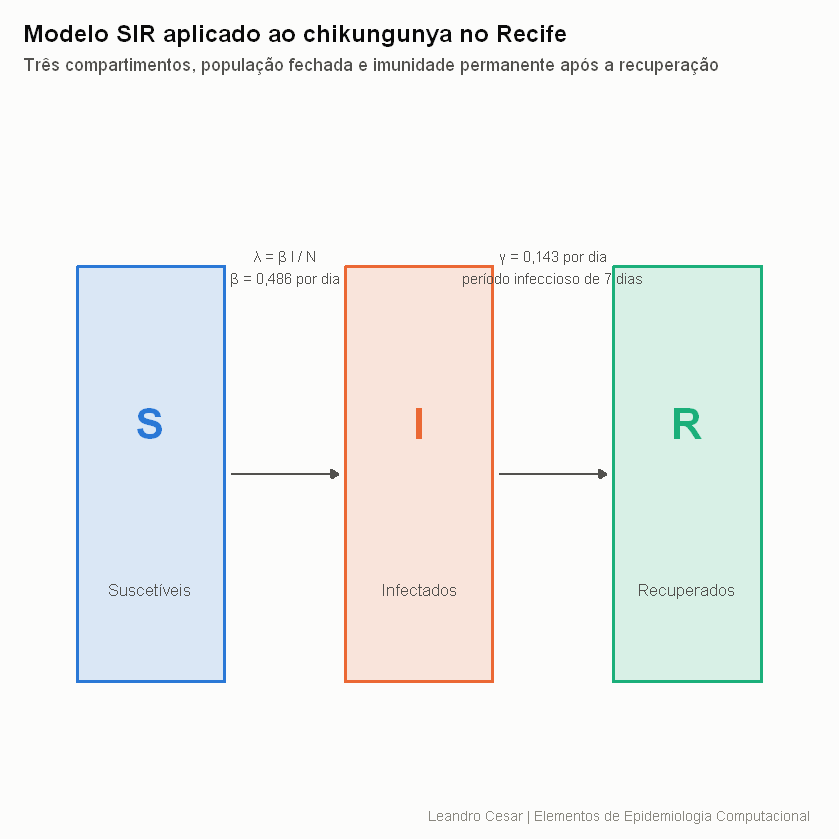

In [3]:
figura_diagrama()

## 3. Parâmetros iniciais e justificativa

| Parâmetro | Valor | Justificativa |
| --- | --- | --- |
| `N` | 1.488.920 | População do Recife no Censo 2022 do IBGE |
| `S0` | `N - 1` | Nenhuma imunidade prévia ao chikungunya antes de 2015 |
| `I0` | 1 | Um único caso introduzido, mesma premissa do caderno do curso |
| `R0` inicial | 0 | Ninguém recuperado no instante da introdução |
| `gamma` | 1/7 por dia | Período infeccioso de 7 dias. A viremia humana dura cerca de 5 a 7 dias e o CDC informa que os sintomas agudos se resolvem em 7 a 10 dias |
| `R0` | 3,4 | Média ponderada de 3,4 com intervalo de 95 por cento entre 2,4 e 4,2, obtida na revisão sistemática de surtos de chikungunya de Liu et al. (2020) |
| `beta` | `R0 * gamma` = 0,486 por dia | Derivado, não arbitrado |
| Horizonte | 180 dias | Suficiente para o surto completar com esses valores |

Duas escolhas merecem destaque.

A primeira é `gamma`. Ele é definido a partir da viremia humana, que é o intervalo em que a pessoa pode
infectar um mosquito. Como o modelo não representa o vetor, o intervalo entre duas infecções humanas
consecutivas fica menor do que o intervalo serial real do chikungunya, que inclui a incubação extrínseca
no mosquito. O efeito prático disso é que a epidemia simulada corre mais rápido do que a observada. O
cenário 7 da seção 5 mostra o que acontece quando esse ritmo é corrigido.

A segunda é `beta`. Em vez de escolher um valor de contágio diretamente, ele é obtido de `R0`, que é a
grandeza efetivamente medida em campo. Assim o parâmetro livre do modelo carrega uma referência
bibliográfica em vez de uma preferência do autor.

In [4]:
parametros <- data.frame(
  Parametro = c("N", "S0", "I0", "R0 inicial", "beta", "gamma", "R0", "Horizonte"),
  Valor = c(milhares(RECIFE$populacao),
            milhares(BASELINE$S0),
            BASELINE$I0,
            BASELINE$R0_compartimento,
            format(round(CHIKV$beta, 3), decimal.mark = ","),
            format(round(CHIKV$gamma, 3), decimal.mark = ","),
            format(CHIKV$R0, decimal.mark = ","),
            paste(BASELINE$duracao_dias, "dias"))
)
parametros

Parametro,Valor
<chr>,<chr>
N,1.488.920
S0,1.488.919
I0,1
R0 inicial,0
beta,"0,486"
gamma,"0,143"
R0,"3,4"
Horizonte,180 dias


## 4. Implementação e dia do pico

A integração numérica usa `deSolve::ode`, chamada por meio de `run_sir_model`, que é a mesma fachada
usada no caderno 4 do curso.

In [5]:
sim <- run_sir_model(beta = CHIKV$beta, gamma = CHIKV$gamma)

head(sim$wide, 10)

,time,S,I,R
,<dbl>,<dbl>,<dbl>,<dbl>
1,0,1488919,1.000000,0.0000000
2,1,1488918,1.408969,0.1704039
3,2,1488918,1.985190,0.4104966
4,3,1488916,2.797068,0.7487797
5,4,1488915,3.940972,1.2254086
6,5,1488913,5.552692,1.8969626
7,6,1488909,7.823545,2.8431596
8,7,1488905,11.023072,4.1763123
9,8,1488898,15.531065,6.0546754


In [6]:
resumo <- epidemic_summary(sim, "Linha de base")

resumo[, c("dia_pico", "S_pico", "I_pico", "R_pico", "prevalencia_pico", "taxa_ataque")]

dia_pico,S_pico,I_pico,R_pico,prevalencia_pico,taxa_ataque
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
44,463374.8,514377.5,511167.8,0.3454702,0.9620277


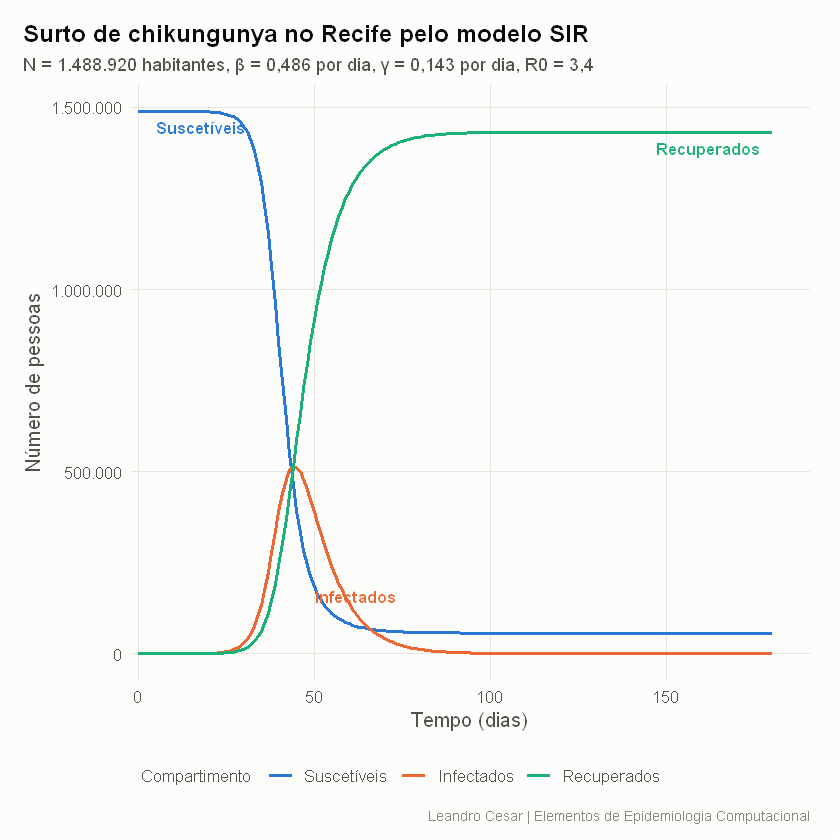

In [7]:
figura_linha_base(sim)

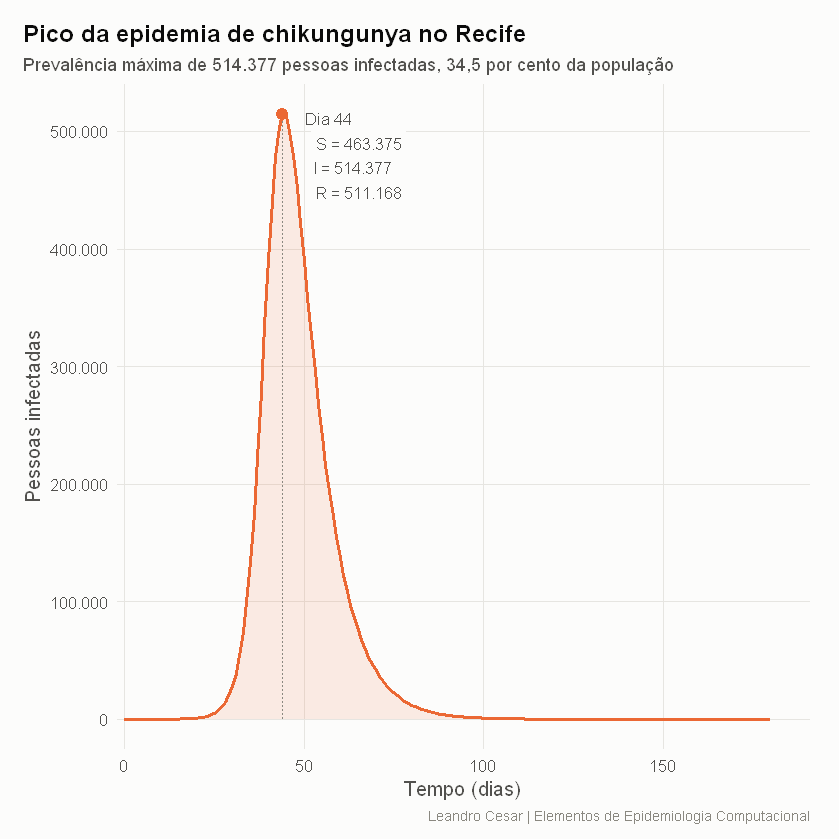

In [8]:
figura_pico(sim, resumo)

### Resposta ao item 4

**A epidemia atinge o pico no dia 44.** Nesse dia os compartimentos contêm:

| Compartimento | Pessoas | Fração da população |
| --- | --- | --- |
| Suscetíveis | 463.375 | 31,1 por cento |
| Infectados | 514.377 | 34,5 por cento |
| Recuperados | 511.168 | 34,3 por cento |

O modelo se comporta como a teoria prevê. Na malha diária o pico cai no dia 44, e refinando o passo para
0,05 dia ele aparece em 44,35 dias, com 515.089 infectados. Esse valor coincide com a expressão analítica
da prevalência máxima, que é

$$\frac{I_{max}}{N} = 1 - \frac{1 + \ln R_0}{R_0} = 0{,}346$$

e o número de suscetíveis no instante do pico coincide com `N / R0`, que é 437.918 pessoas. É esse o
significado geométrico do pico: ele acontece exatamente quando a reserva de suscetíveis cruza o limiar
`N / R0`, e não em um instante arbitrário.

In [9]:
fino <- refina_pico(sim)
N <- RECIFE$populacao

comparacao <- data.frame(
  Grandeza = c("Prevalência no pico", "Suscetíveis no pico", "Taxa de ataque final"),
  Simulado = c(milhares(fino$I), milhares(fino$S),
               paste0(format(round(100 * resumo$taxa_ataque, 2), decimal.mark = ","), " por cento")),
  Teorico = c(milhares(pico_teorico(CHIKV$R0) * N), milhares(N / CHIKV$R0),
              paste0(format(round(100 * tamanho_final_teorico(CHIKV$R0), 2), decimal.mark = ","), " por cento"))
)
comparacao

Grandeza,Simulado,Teorico
<chr>,<chr>,<chr>
Prevalência no pico,515.089,515.089
Suscetíveis no pico,436.922,437.918
Taxa de ataque final,"96,2 por cento","96,2 por cento"


## 5. Variações nas taxas de contágio e de recuperação

São oito cenários, que cobrem as três situações sugeridas no enunciado: taxas iguais, recuperação fixa com
contágio variando, e contágio fixo com recuperação variando. Dois cenários extras completam a análise: um
que preserva `R0` alterando as duas taxas na mesma proporção, e um que representa uma intervenção de
controle vetorial.

In [10]:
cenarios <- run_scenarios()

num <- function(x, casas) format(round(x, casas), decimal.mark = ",", nsmall = casas)

tabela <- with(cenarios$resumo, data.frame(
  ID = id,
  `Cenário` = as.character(cenario),
  beta = num(beta, 3),
  gamma = num(gamma, 3),
  R0 = num(R0, 2),
  `Dia do pico` = ifelse(R0 > 1, as.character(dia_pico), "sem surto"),
  `Infectados no pico` = ifelse(R0 > 1, milhares(I_pico), "sem surto"),
  `Ataque final` = paste0(num(100 * taxa_ataque, 1), " por cento"),
  check.names = FALSE
))
tabela

ID,Cenário,beta,gamma,R0,Dia do pico,Infectados no pico,Ataque final
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Linha de base,"0,486","0,143","3,40",44,514.377,"96,2 por cento"
2,Taxas iguais,"0,143","0,143","1,00",sem surto,sem surto,"0,0 por cento"
3,Contágio pela metade,"0,243","0,143","1,70",136,148.295,"69,1 por cento"
4,Contágio 50 por cento maior,"0,729","0,143","5,10",27,721.315,"99,4 por cento"
5,Viremia de 14 dias,"0,486","0,071","6,80",39,850.233,"99,9 por cento"
6,"Recuperação em 1,7 dia","0,486","0,600","0,81",sem surto,sem surto,"0,0 por cento"
7,"Mesmo R0, ritmo pela metade","0,243","0,071","3,40",89,514.926,"96,2 por cento"
8,Controle vetorial do Aedes,"0,194","0,143","1,36",243,57.494,"47,8 por cento"


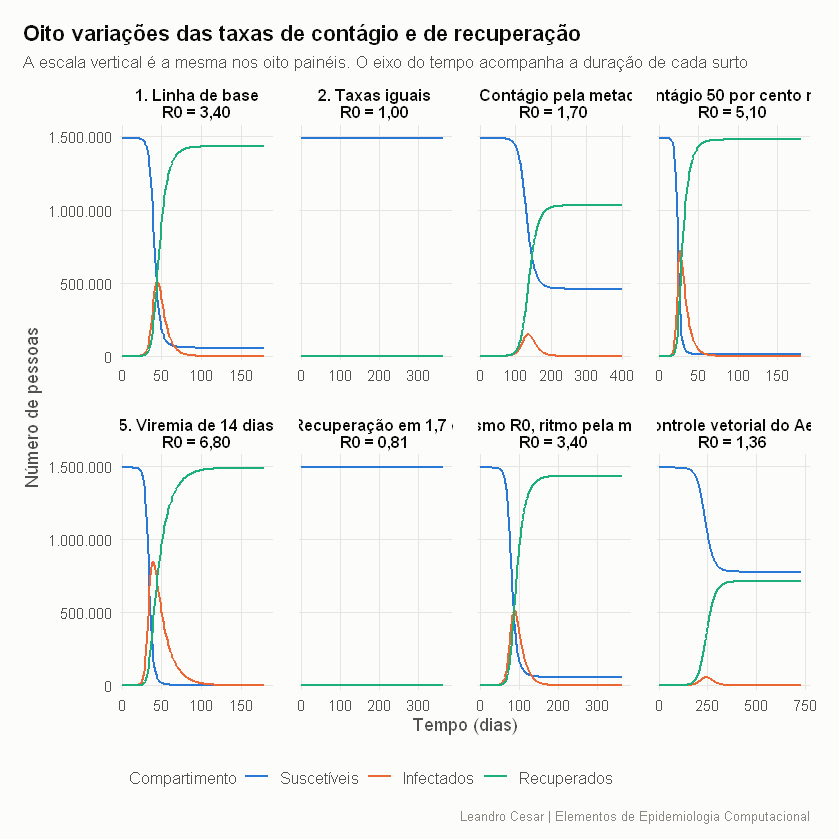

In [11]:
figura_cenarios_painel(cenarios$curvas, cenarios$resumo)

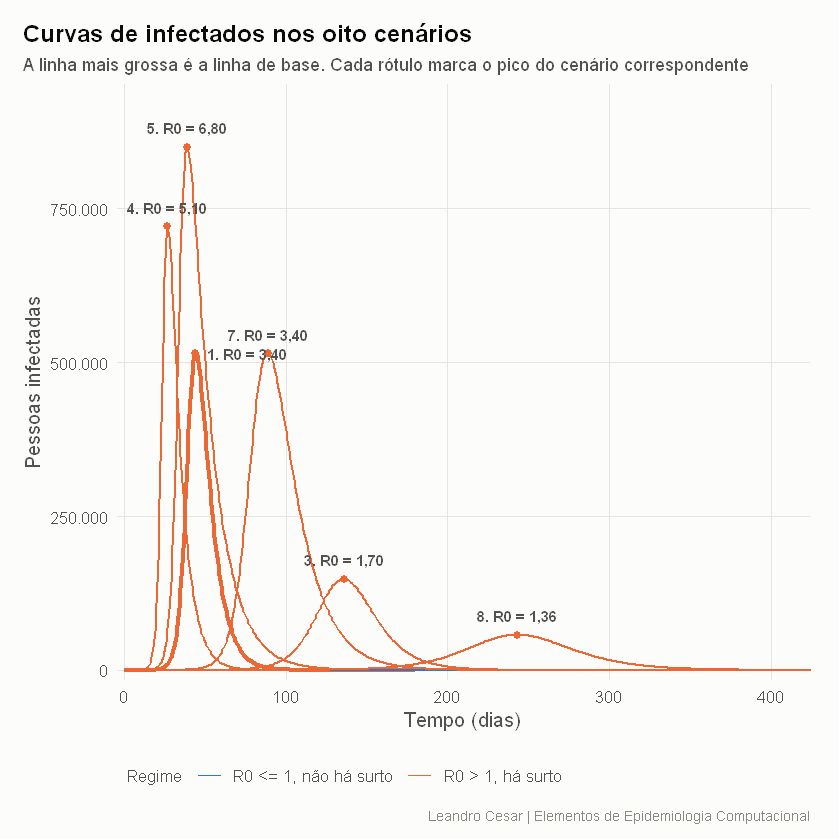

In [12]:
figura_cenarios_infectados(cenarios$curvas, cenarios$resumo)

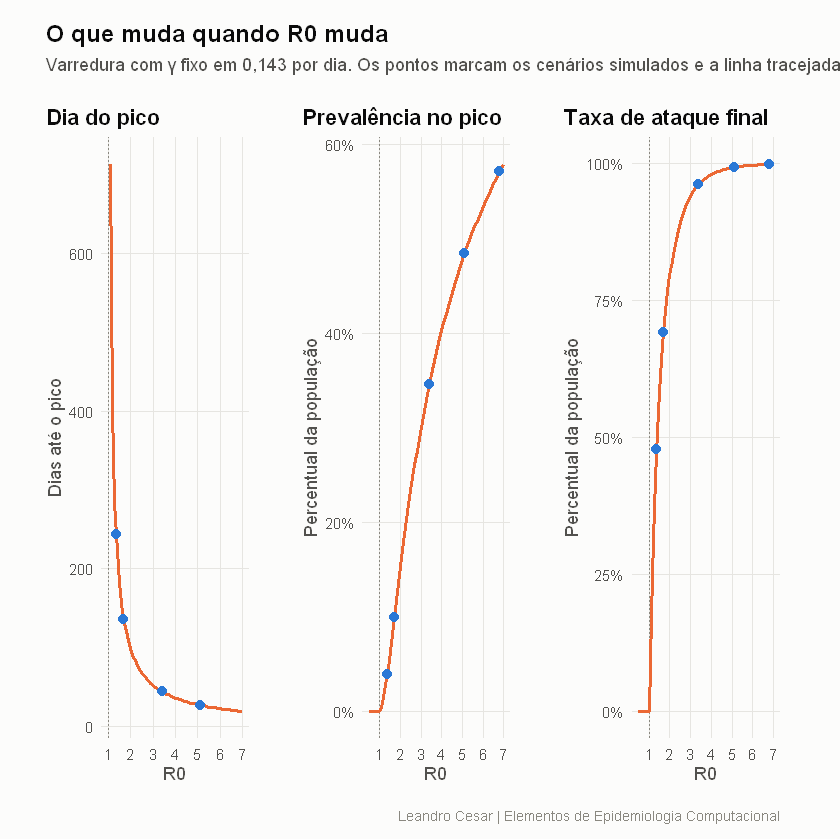

In [13]:
figura_limiar(cenarios$resumo)

### Comentário dos resultados

**Cenário 2, taxas iguais.** Com `beta` igual a `gamma`, o valor de `R0` é exatamente 1 e nada acontece.
Cada pessoa infectada transmite em média para exatamente uma outra, então a prevalência não cresce nem
decai. É o limiar epidêmico, e ele separa dois comportamentos qualitativamente diferentes, e não apenas
dois surtos de tamanhos diferentes.

**Cenários 3 e 4, recuperação fixa e contágio variando.** Aumentar o contágio adianta e agrava o surto.
Passando de `beta` igual a 0,243 para 0,729, o pico salta do dia 136 para o dia 27 e sobe de 148 mil para
721 mil infectados. A curva também fica mais estreita: quanto mais rápido o surto sobe, mais rápido ele
esgota os suscetíveis e desce.

**Cenários 5 e 6, contágio fixo e recuperação variando.** A taxa de recuperação atua no sentido oposto.
Dobrando o período infeccioso de 7 para 14 dias, `R0` dobra para 6,8 e o pico chega a 850 mil pessoas.
No outro extremo, uma recuperação em 1,7 dia derruba `R0` para 0,81 e o surto não ocorre. Vale notar que
o cenário 6 não representa um surto pequeno: ele representa a ausência de surto, assim como o cenário 2.

**Cenário 7, mesmo R0 com ritmo pela metade.** Dividindo `beta` e `gamma` pelo mesmo fator, `R0` permanece
em 3,4. O resultado é revelador: a altura do pico e a taxa de ataque final são idênticas às da linha de
base, mas o pico passa do dia 44 para o dia 89, ou seja, exatamente o dobro do tempo. **A razão entre as
taxas determina o tamanho da epidemia, e a escala das taxas determina apenas a sua velocidade.** É por
isso que a subestimação do intervalo serial, apontada na seção 3, afeta o calendário do surto mas não o
número de pessoas atingidas.

**Cenário 8, controle vetorial.** Reduzir o contágio em 60 por cento, que é o efeito esperado de uma
campanha eficaz contra criadouros do `Aedes`, baixa `R0` para 1,36. O pico cai de 514 mil para 57 mil
infectados, uma redução de quase nove vezes, e é empurrado do dia 44 para o dia 243. A taxa de ataque cai
de 96 para 48 por cento. Este é o achatamento da curva no modelo mais simples possível.

**A leitura conjunta.** A terceira figura desta seção mostra por que os cenários se organizam assim. A
prevalência no pico e a taxa de ataque final dependem apenas de `R0`, e as duas crescem rápido logo acima
do limiar e depois saturam. Já o dia do pico depende também da escala das taxas, e por isso apenas os
cenários que compartilham o mesmo `gamma` aparecem naquele primeiro painel. Ganhos marginais em `R0` valem
muito perto de 1 e quase nada acima de 4, o que tem consequência prática direta: intervenções valem mais
quando aplicadas cedo, enquanto `R0` efetivo ainda está próximo do limiar.

## 6. Lacunas do modelo

O SIR clássico entrega o formato certo da epidemia mas erra em pontos que importam para a chikungunya.

**O mosquito não existe no modelo.** A transmissão do chikungunya não é direta. Ela passa pelo `Aedes
aegypti`, e o ciclo completo inclui a incubação extrínseca no mosquito, que leva de 2 a 6 dias. Ao
comprimir esse ciclo dentro de um único `beta`, o modelo perde a densidade de vetores, a sazonalidade das
chuvas no Recife e qualquer possibilidade de avaliar intervenção sobre criadouros de forma explícita. O
cenário 8 só consegue representar controle vetorial como uma redução arbitrada de `beta`, e não como
consequência de uma ação sobre a população de mosquitos.

**Não há compartimento de expostos.** A incubação intrínseca no ser humano é de 4 a 8 dias segundo a
Organização Mundial da Saúde, mas no SIR quem é infectado transmite imediatamente. Isso acelera
artificialmente a fase inicial do surto. Um modelo SEIR corrigiria esse ponto.

**A mistura homogênea não descreve o Recife.** O modelo supõe que qualquer suscetível tem a mesma chance
de encontrar qualquer infectado. Numa cidade com a heterogeneidade socioespacial do Recife, onde
saneamento, armazenamento de água e densidade domiciliar variam muito entre bairros, a transmissão é
fortemente agrupada no espaço. A consequência é visível nos números: o modelo prevê taxa de ataque de 96
por cento, enquanto o inquérito sorológico conduzido em Pau da Lima, em Salvador, encontrou apenas 11,8
por cento de soroprevalência após a epidemia de 2015 (Anjos et al., 2020). **A discrepância entre 96 e
11,8 por cento é a medida do custo de supor mistura homogênea**, e é a lacuna mais grave deste modelo.

**A população é fechada.** Não há nascimentos, óbitos nem mobilidade. O Recife é o centro de uma região
metropolitana com mais de 4 milhões de habitantes e fluxo pendular diário intenso, que o modelo ignora
por completo.

**Subnotificação e confusão diagnóstica.** Em 2015 e 2016 circulavam simultaneamente dengue, zika e
chikungunya no Recife, com quadros clínicos parecidos. Além disso, boa parte das infecções por
chikungunya é assintomática ou oligossintomática. Qualquer comparação entre o `I` do modelo e a série de
casos notificados precisa de uma fração de notificação, que o SIR não possui.

**O compartimento R esconde a cronificação.** O modelo trata a recuperação como um estado final único.
Na chikungunya, uma parcela relevante dos infectados desenvolve artralgia crônica que pode durar meses ou
anos, com impacto sobre capacidade laboral e demanda por serviços de saúde. Do ponto de vista do modelo
essas pessoas estão recuperadas, e do ponto de vista do sistema de saúde não estão.

**As taxas são constantes.** `beta` não varia no tempo, então o modelo não representa mudanças de
comportamento, campanhas de mobilização, sazonalidade nem qualquer intervenção que comece em uma data
específica. Só é possível comparar cenários alternativos inteiros, como foi feito na seção 5.

### Para onde este modelo cresce

As extensões naturais são, em ordem de esforço, um SEIR que separe expostos de infectantes, um modelo
hospedeiro e vetor com compartimentos explícitos para o mosquito, e um autômato celular sobre a malha de
bairros do Recife que substitua a mistura homogênea por vizinhança espacial. Essa última é justamente a
direção seguida no restante da disciplina.

## Referências

- ANJOS, R. O. et al. Transmission of Chikungunya Virus in an Urban Slum, Brazil. *Emerging Infectious
  Diseases*, v. 26, n. 7, p. 1364 a 1373, 2020. DOI 10.3201/eid2607.190846.
- IBGE. *Censo Demográfico 2022*. Rio de Janeiro: Instituto Brasileiro de Geografia e Estatística, 2023.
- KERMACK, W. O.; McKENDRICK, A. G. A Contribution to the Mathematical Theory of Epidemics.
  *Proceedings of the Royal Society A*, v. 115, n. 772, p. 700 a 721, 1927.
- LIU, Y. et al. Basic Reproduction Number of Chikungunya Virus Transmitted by Aedes Mosquitoes.
  *Emerging Infectious Diseases*, v. 26, n. 10, 2020. DOI 10.3201/eid2610.190957.
- MAGALHAES, T. et al. Zika virus displacement by a chikungunya outbreak in Recife, Brazil.
  *PLOS Neglected Tropical Diseases*, v. 11, n. 11, e0006055, 2017. DOI 10.1371/journal.pntd.0006055.
- SOETAERT, K.; PETZOLDT, T.; SETZER, R. W. Solving Differential Equations in R: Package deSolve.
  *Journal of Statistical Software*, v. 33, n. 9, 2010.
- WORLD HEALTH ORGANIZATION. *Chikungunya fact sheet*. Genebra: OMS.